In [29]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Device selection

In [30]:
from qiskit_ibm_runtime import QiskitRuntimeService
from cobos.tokens import ibm_token, group_instance, group_instance2
# from fradm.tokens import ibm_token, group_instance

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
device = "ibm_torino"
# device = "ibm_marrakesh"

fractional_gates = False

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device, use_fractional_gates=fractional_gates)

# Simulation settings

In [31]:
from z2chain.gdd import random, constant, counteract_rotation, from_matrix, zero_mean_gdd_matrix
from z2chain.postselection import bias_corrected_get_recovered_samples_dicts
from utils.hexec import ExecDB
from functools import partial

L = 21
J = 5
h = 0.8
lamb = 1

x_basis = False

particle_pair_left_position = L//2 - 3
particle_pair_length = 6

final_time = 5
dt = 0.125
steps = 40
desired_error = 1e-2

shots = 75000
confidence = 0.7

odr = True
postselect_odr = True
flip_threshold = 4
# recovery = bias_corrected_get_recovered_samples_dicts
recovery = True
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = partial(from_matrix, matrix=zero_mean_gdd_matrix(L, steps))
# g_func = None

if callable(g_func):
    g_func.__name__ = from_matrix.__name__

g_func_arr = [None]*3 + [g_func]*3

sampler_options_tuples = [
    (False, False),
    (False, True),
    (True, True)
]*2

sampler_options_arr = [{
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": opts[0],
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": opts[1],
        "enable_measure": opts[1],
        "num_randomizations": shots//100,
        "shots_per_randomization": 100
    },
    "experimental": {
        "execution_path": "gen3-turbo"
    }
} for opts in sampler_options_tuples]

execution_database = "z2_chain_jobs_postselection_noise_mitigation_debug.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

curated_data_folder_path = "Curated Data/"

# Error guarantees

In [32]:
from z2chain.circs import trotter_dt
import numpy as np

error_dt = trotter_dt(desired_error, L, J, h, lamb)
nsteps = np.ceil(final_time / error_dt)

print(f"To guarantee the desired error, Δt should be:\nΔt = {error_dt:.5f}")
print(f"To correctly reach the desired final time, the number of layers required is:\nN = {nsteps} ({nsteps*4} 2Qb depth)")

To guarantee the desired error, Δt should be:
Δt = 0.02672
To correctly reach the desired final time, the number of layers required is:
N = 188 (752 2Qb depth)


In [33]:
from z2chain.circs import trotter_error

settings_error = trotter_error(dt, L, J, h, lamb)
sim_max_nlayers = np.ceil(final_time / dt).astype(int)

print(f"With the current simultation settings Δt is at most\nΔt = {dt:.5f}")
print(f"The error per layer commited in the wrost case is\nƐ = {settings_error:.05}")
print(f"The number of layers at the final evolution time is\nN = {sim_max_nlayers} ({4*sim_max_nlayers} 2Qb depth)")

With the current simultation settings Δt is at most
Δt = 0.12500
The error per layer commited in the wrost case is
Ɛ = 1.0237
The number of layers at the final evolution time is
N = 40 (160 2Qb depth)


# Load Jobs

In [35]:
from utils.postselection_multithreaded import load_postselected_jobs
import pickle
import os

job_index = 0

verbose = True
overwrite = False

observables = []
observables_confidence = []
samples_dicts = []
postselected_samples_dicts = []
for i, (g_func, sampler_options) in enumerate(zip(g_func_arr, sampler_options_arr)):
    if verbose: print(f"\rg_func: {g_func.__name__ if callable(g_func) else None} / Sampler options: {i}".ljust(100), end="")
    curated_data_filepath = os.path.join(curated_data_folder_path, f"z2chainquench_curated_data_{device}_L_{L}_J_{J}_h_{h}_lamb_{lamb}_g_{g_func.__name__ if callable(g_func) else None}_final_time_{final_time}_dt_{dt}_steps_{steps}_shots_{shots}_ppos_{particle_pair_left_position}_pl_{particle_pair_length}_ft_{flip_threshold}_DD_{sampler_options["dynamical_decoupling"]["enable"]}_PT_{sampler_options["twirling"]["enable_gates"]}_pODR_{postselect_odr}.pkl")
    with open(curated_data_filepath, "rb") as f:
        this_observables, this_observables_confidence, this_samples_dicts, this_postselected_samples_dicts, layout = pickle.load(f)
    observables.append(this_observables)
    observables_confidence.append(this_observables_confidence)
    samples_dicts.append(this_samples_dicts)
    postselected_samples_dicts.append(this_postselected_samples_dicts)

g_func: from_matrix / Sampler options: 5                                                           

# Load noiseless simulation

In [36]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
from juliacall import Main as jl, convert as jlconvert
import numpy as np
import os

overwrite = False
itensors_cutoff = 1e-12

path_to_julia_tn = "../../z2chain/Z2HiggsChainDynamics.jl"
jl.seval(f"include(\"{path_to_julia_tn}\")")
jl.seval("using .Z2HiggsChainDynamics")

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_steps_{steps}_L_{L}_J_{J}_h_{h:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_xbasis_{x_basis}_steps_{steps}_ploteach_{1}_cutoff_{itensors_cutoff}.npy"
if os.path.exists(filepath) and not overwrite:
    itensors_observables = load_site_gauge_observable_matrix(filepath)
else:
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    mpos = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    itensors_observables = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, mpos, J, h, lamb, particle_pair_left_position, particle_pair_length, final_time, steps, x_basis, 1, itensors_cutoff)
    itensors_observables = np.array(itensors_observables)
    if overwrite:
        save_site_gauge_observable_matrix(itensors_observables, filepath)

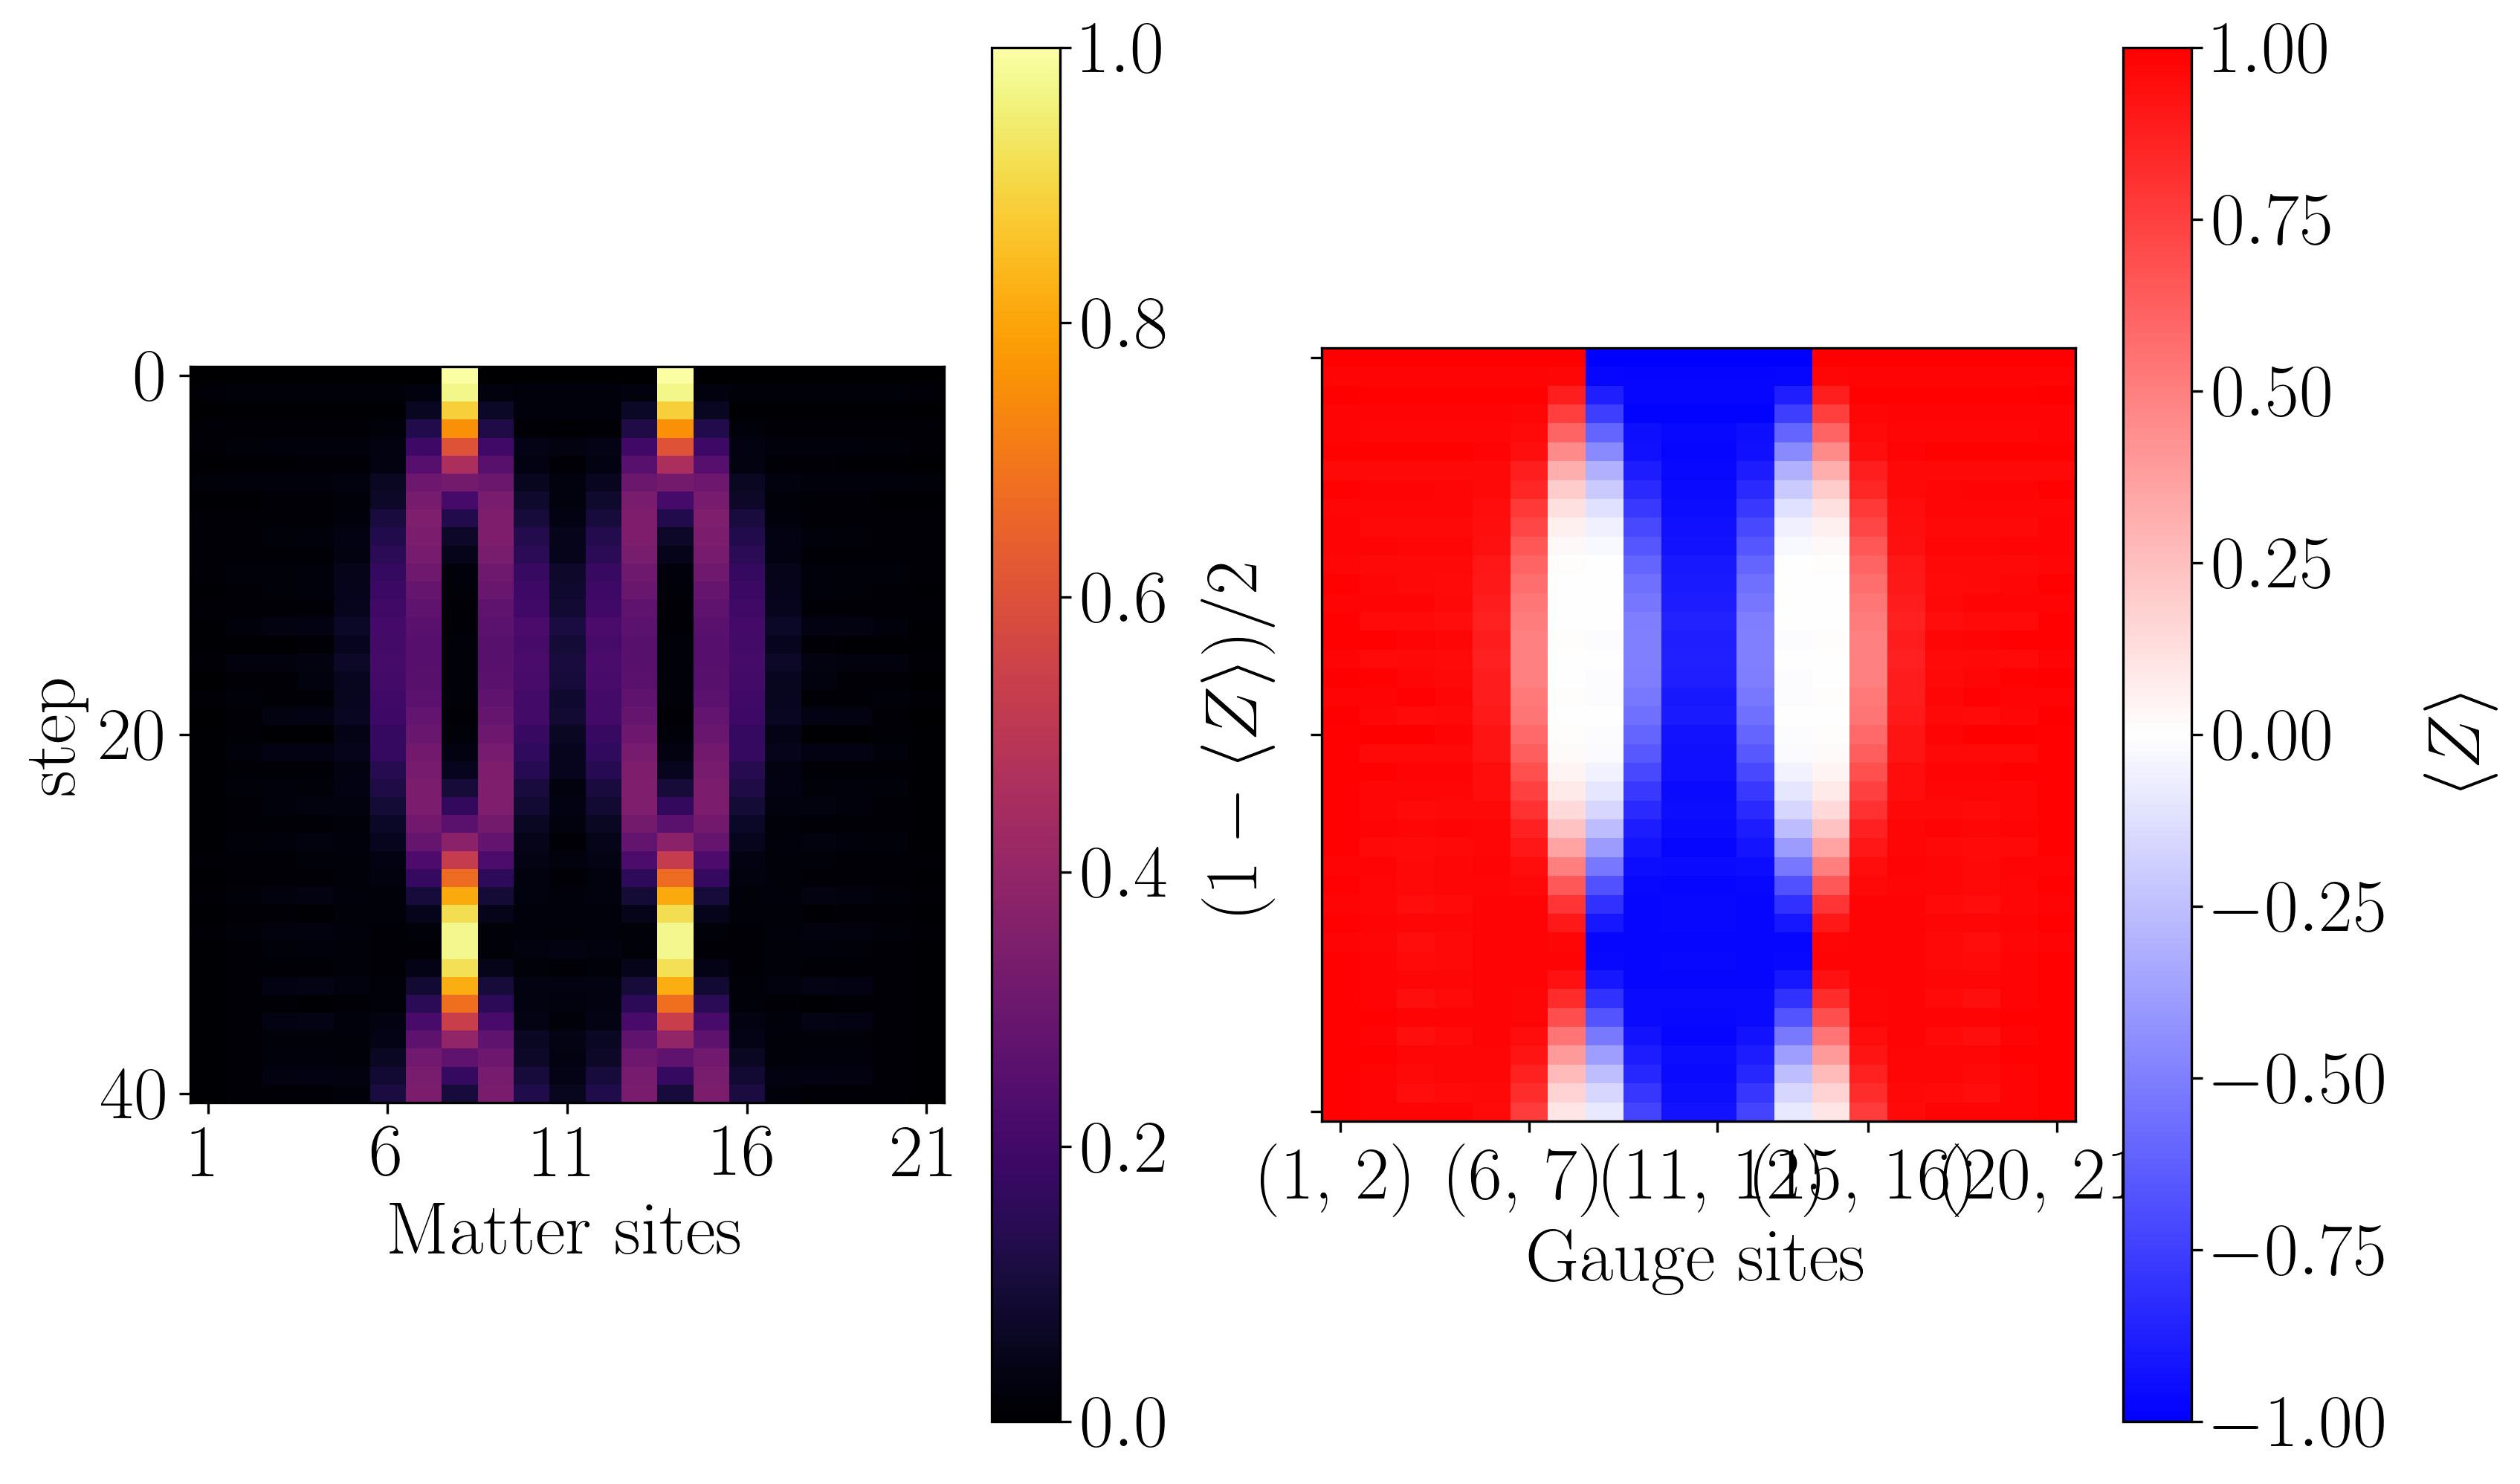

In [37]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(itensors_observables)

# Plots

## Clean data comparison

/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/utils/plotting.py:456: RuntimeWarning: Mean of empty slice
  mean_deviations = np.nanmean(np.abs(observable_matrices_1 - observable_matrices_2), axis=-1)


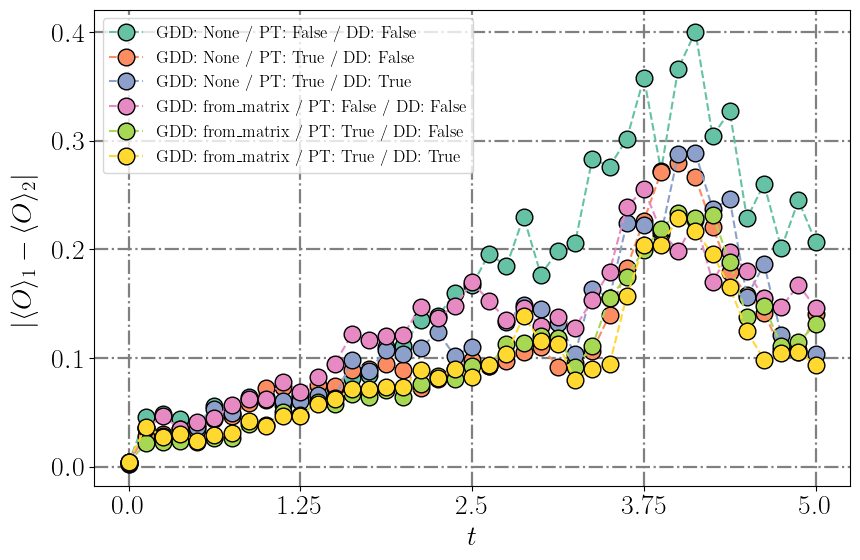

In [38]:
from utils.plotting import plot_mean_deviations

hardware_observables = [obs[0] for obs in observables]
to_plot_itensors_observables = [itensors_observables.copy()]*len(hardware_observables)

x_ticks = [
    np.arange(0, steps+1, (steps)//4),
    np.linspace(0, final_time, 5)
]

labels = [f"GDD: {g_func.__name__ if callable(g_func) else None} / PT: {sampler_options["twirling"]["enable_gates"]} / DD: {sampler_options["dynamical_decoupling"]["enable"]}" for g_func, sampler_options in zip(g_func_arr, sampler_options_arr)]

plot_mean_deviations(hardware_observables, to_plot_itensors_observables, x_ticks=x_ticks, x_label="$t$", labels=labels)

## GDD from_matrix PT True DD True error through postprocessing

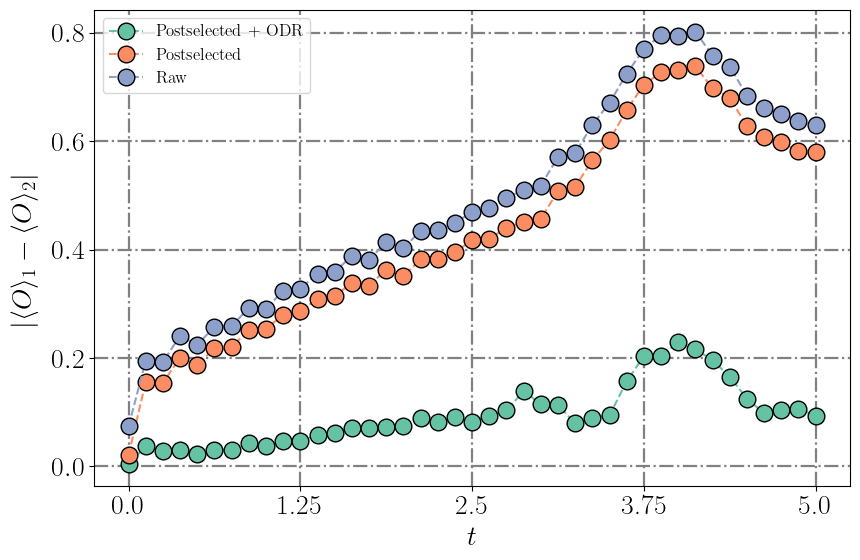

In [39]:
settings_index = -1

hardware_observables = [observables[settings_index][i] for i in range(4) if i != 2]
to_plot_itensors_observables = [itensors_observables.copy()]*len(hardware_observables)

x_ticks = [
    np.arange(0, steps+1, (steps)//4),
    np.linspace(0, final_time, 5)
]

labels = ["Postselected + ODR", "Postselected", "Raw"]
plot_mean_deviations(hardware_observables, to_plot_itensors_observables, x_ticks=x_ticks, x_label="$t$", labels=labels)

## GDD None PT True DD False error through postprocessing

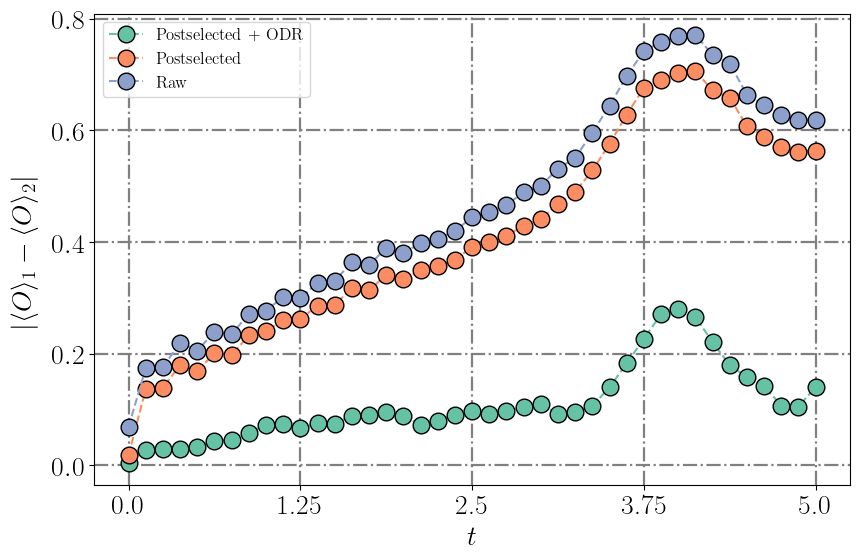

In [40]:
best_index = 1

hardware_observables = [observables[best_index][i] for i in range(4) if i != 2]
to_plot_itensors_observables = [itensors_observables.copy()]*len(hardware_observables)

x_ticks = [
    np.arange(0, steps+1, (steps)//4),
    np.linspace(0, final_time, 5)
]

labels = ["Postselected + ODR", "Postselected", "Raw"]
plot_mean_deviations(hardware_observables, to_plot_itensors_observables, x_ticks=x_ticks, x_label="$t$", labels=labels)